In [1]:
import os
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from rdm import *
from rsa import *

from scipy.stats import spearmanr, rankdata, linregress
from sklearn.linear_model import LinearRegression
from sklearn.utils import resample
from numpy.random import permutation
from joblib import Parallel, delayed

In [2]:
# mov1 - mov2, movie playing
# movies are 50fps
out_base_path='/home/bonaiuto/infant_face_eeg/derivatives/9m'

In [3]:
f_cond=[
    ('F01','Joy','unshuffled'),
    ('F01','Joy','shuffled'),
    ('F03','Joy','unshuffled'),
    ('F03','Joy','shuffled'),
    ('F02','Sadness','unshuffled'),
    ('F02','Sadness','shuffled'),
    ('F04','Sadness','unshuffled'),
    ('F04','Sadness','shuffled'),
    ('F06','MouthOpening','unshuffled'),
    ('F06','MouthOpening','shuffled'),
    ('F07','MouthOpening','unshuffled'),
    ('F07','MouthOpening','shuffled')
]
f_label=[]
for (actor,movement,status) in f_cond:
    f_label.append('{} {} {}'.format(actor,movement,status))

In [4]:
fname=os.path.join(out_base_path, 'model_static_rdms.npz')
with np.load(fname, allow_pickle=True) as data:
    model_rdms=data['model_rdms'].item()

Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/102/NEARICA_NF/04_rereferenced_data/102.events_rereferenced_ima1_data.set...
Not setting metadata
29 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/103/NEARICA_NF/04_rereferenced_data/103.events_rereferenced_ima1_data.set...
Not setting metadata
50 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/108/NEARICA_NF/04_rereferenced_data/108.events_rereferenced_ima1_data.set...
Not setting metadata
53 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/109/NEARICA_NF/04_rereferenced_data/109.events_rereferenced_ima1_data.set...
Not setting metadata
61 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/111/NEARICA_NF/04_rereferenced_data/111.events_rereferenced_ima1_data.set...
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/112/NEARICA_NF/04_rereferenced_data/112.events_rereferenced_ima1_data.set...
Not setting metadata
41 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


... (14 outputs left out)

Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/141/NEARICA_NF/04_rereferenced_data/141.events_rereferenced_ima1_data.set...
Not setting metadata
61 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/148/NEARICA_NF/04_rereferenced_data/148.events_rereferenced_ima1_data.set...
Not setting metadata
80 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/149/NEARICA_NF/04_rereferenced_data/149.events_rereferenced_ima1_data.set...
Not setting metadata
101 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Identifying common channels ...
No projector specified for this dataset. Please consider the method self.add_proj.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


/home/bonaiuto/infant_face_eeg/src/rsa.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


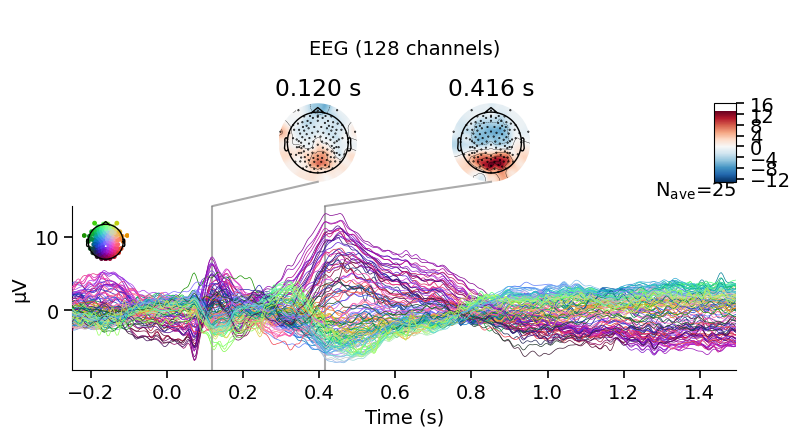

In [40]:
base_data_path='/home/common/bonaiuto/infant_9m_face_eeg/derivatives'

grand_average=get_grand_average(base_data_path, evt='_ima1', crop_lims=(-.25,None))

# Plot the grand average

plt.rcParams.update({
    'font.size': 14,
    'axes.spines.right': False,
    'axes.spines.top': False,
    'xtick.major.size': 6,
    'xtick.major.width': 1.2,
    'ytick.major.size': 6,
    'ytick.major.width': 1.2,
    'legend.frameon': False,
    'legend.handletextpad': 0.1,
    'svg.fonttype': 'none',
    'text.usetex': False
})

ts_fig=grand_average.plot_joint(times=[.12,.416])
ts_fig.set_size_inches([3.287, 4.2])
ts_fig.savefig('../output/butterfly_9m_dynamic_neutral.png')
ts_fig.savefig('../output/butterfly_9m_dynamic_neutral.pdf')

In [6]:
win_sz_ms = 500    

In [7]:
n_trials(f_cond, base_data_path, evt='_ima1', epoch_evt='ima1')

Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/102/NEARICA_NF/04_rereferenced_data/102.events_rereferenced_ima1_data.set...
Not setting metadata
29 matching events found
No baseline correction applied
0 projection items activated
Ready.
102: F01 Joy unshuffled=2
102: F01 Joy shuffled=3
102: F03 Joy unshuffled=5
102: F03 Joy shuffled=2
102: F02 Sadness unshuffled=1
102: F02 Sadness shuffled=2
102: F04 Sadness unshuffled=3
102: F04 Sadness shuffled=0
102: F06 MouthOpening unshuffled=3
102: F06 MouthOpening shuffled=1
102: F07 MouthOpening unshuffled=3
102: F07 MouthOpening shuffled=0
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/103/NEARICA_NF/04_rereferenced_data/103.events_rereferenced_ima1_data.set...
Not setting metadata
50 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


103: F01 Joy unshuffled=5
103: F01 Joy shuffled=4
103: F03 Joy unshuffled=6
103: F03 Joy shuffled=1
103: F02 Sadness unshuffled=8
103: F02 Sadness shuffled=2
103: F04 Sadness unshuffled=4
103: F04 Sadness shuffled=2
103: F06 MouthOpening unshuffled=6
103: F06 MouthOpening shuffled=3
103: F07 MouthOpening unshuffled=7
103: F07 MouthOpening shuffled=1
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/108/NEARICA_NF/04_rereferenced_data/108.events_rereferenced_ima1_data.set...
Not setting metadata
53 matching events found
No baseline correction applied
0 projection items activated
Ready.
108: F01 Joy unshuffled=3
108: F01 Joy shuffled=3
108: F03 Joy unshuffled=7
108: F03 Joy shuffled=2
108: F02 Sadness unshuffled=3
108: F02 Sadness shuffled=4
108: F04 Sadness unshuffled=7
108: F04 Sadness shuffled=1
108: F06 MouthOpening unshuffled=4
108: F06 MouthOpening shuffled=2
108: F07 MouthOpening unshuffled=8
108: F07 MouthOpening shuffled=3
Extracting parameters from

/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


109: F01 Joy unshuffled=7
109: F01 Joy shuffled=1
109: F03 Joy unshuffled=4
109: F03 Joy shuffled=2
109: F02 Sadness unshuffled=2
109: F02 Sadness shuffled=3
109: F04 Sadness unshuffled=7
109: F04 Sadness shuffled=0
109: F06 MouthOpening unshuffled=7
109: F06 MouthOpening shuffled=2
109: F07 MouthOpening unshuffled=5
109: F07 MouthOpening shuffled=5
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/111/NEARICA_NF/04_rereferenced_data/111.events_rereferenced_ima1_data.set...
Not setting metadata
59 matching events found
No baseline correction applied
0 projection items activated
Ready.
111: F01 Joy unshuffled=4
111: F01 Joy shuffled=1
111: F03 Joy unshuffled=7
111: F03 Joy shuffled=3
111: F02 Sadness unshuffled=7
111: F02 Sadness shuffled=5
111: F04 Sadness unshuffled=8
111: F04 Sadness shuffled=2
111: F06 MouthOpening unshuffled=8
111: F06 MouthOpening shuffled=2
111: F07 MouthOpening unshuffled=5
111: F07 MouthOpening shuffled=2
Extracting parameters from

/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


... (16 outputs left out)

139: F01 Joy unshuffled=7
139: F01 Joy shuffled=0
139: F03 Joy unshuffled=1
139: F03 Joy shuffled=2
139: F02 Sadness unshuffled=3
139: F02 Sadness shuffled=1
139: F04 Sadness unshuffled=3
139: F04 Sadness shuffled=4
139: F06 MouthOpening unshuffled=4
139: F06 MouthOpening shuffled=1
139: F07 MouthOpening unshuffled=5
139: F07 MouthOpening shuffled=0
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/141/NEARICA_NF/04_rereferenced_data/141.events_rereferenced_ima1_data.set...
Not setting metadata
61 matching events found
No baseline correction applied
0 projection items activated
Ready.
141: F01 Joy unshuffled=5
141: F01 Joy shuffled=4
141: F03 Joy unshuffled=9
141: F03 Joy shuffled=2
141: F02 Sadness unshuffled=9
141: F02 Sadness shuffled=1
141: F04 Sadness unshuffled=5
141: F04 Sadness shuffled=0
141: F06 MouthOpening unshuffled=4
141: F06 MouthOpening shuffled=5
141: F07 MouthOpening unshuffled=8
141: F07 MouthOpening shuffled=2
Extracting parameters from

/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')
/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


No baseline correction applied
0 projection items activated
Ready.
148: F01 Joy unshuffled=9
148: F01 Joy shuffled=2
148: F03 Joy unshuffled=8
148: F03 Joy shuffled=3
148: F02 Sadness unshuffled=8
148: F02 Sadness shuffled=3
148: F04 Sadness unshuffled=11
148: F04 Sadness shuffled=2
148: F06 MouthOpening unshuffled=9
148: F06 MouthOpening shuffled=3
148: F07 MouthOpening unshuffled=9
148: F07 MouthOpening shuffled=3
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/149/NEARICA_NF/04_rereferenced_data/149.events_rereferenced_ima1_data.set...
Not setting metadata
101 matching events found
No baseline correction applied
0 projection items activated
Ready.
149: F01 Joy unshuffled=12
149: F01 Joy shuffled=1
149: F03 Joy unshuffled=11
149: F03 Joy shuffled=5
149: F02 Sadness unshuffled=13
149: F02 Sadness shuffled=1
149: F04 Sadness unshuffled=12
149: F04 Sadness shuffled=3
149: F06 MouthOpening unshuffled=10
149: F06 MouthOpening shuffled=7
149: F07 MouthOpenin

/home/bonaiuto/infant_face_eeg/src/rsa.py:64: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


In [8]:
compute_data_dynamic_rdm(
    'static', 
    f_cond, 
    base_data_path, 
    win_sz_ms, 
    out_base_path, 
    evt='_ima1', 
    epoch_evt='ima1', 
    crop_lims=(-.5, None)
)

Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/102/NEARICA_NF/04_rereferenced_data/102.events_rereferenced_ima1_data.set...
Not setting metadata
29 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rdm.py:177: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/103/NEARICA_NF/04_rereferenced_data/103.events_rereferenced_ima1_data.set...
Not setting metadata
50 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rdm.py:177: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/108/NEARICA_NF/04_rereferenced_data/108.events_rereferenced_ima1_data.set...
Not setting metadata
53 matching events found


/home/bonaiuto/infant_face_eeg/src/rdm.py:177: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


... (41 outputs left out)

/home/bonaiuto/infant_face_eeg/src/rdm.py:177: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Not setting metadata
80 matching events found
No baseline correction applied
0 projection items activated
Ready.
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/149/NEARICA_NF/04_rereferenced_data/149.events_rereferenced_ima1_data.set...


/home/bonaiuto/infant_face_eeg/src/rdm.py:177: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


Not setting metadata
101 matching events found
No baseline correction applied
0 projection items activated
Ready.


In [8]:
test_models=['movement_type', 'landmark', 'au_c', 'contrast', 'gabor']
n_models = len(test_models)

In [9]:
compute_data_model_static_correlations(
    base_data_path, 
    win_sz_ms, 
    model_rdms, 
    test_models, 
    out_base_path, evt='_ima1', 
    exclude_subjects=['119','131'], 
    crop_lims=(-.5, None),
    suffix='_movement_type_contrast_gabor'
)

102
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/102/NEARICA_NF/04_rereferenced_data/102.events_rereferenced_ima1_data.set...
Not setting metadata
29 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:220: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


103
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/103/NEARICA_NF/04_rereferenced_data/103.events_rereferenced_ima1_data.set...
Not setting metadata
50 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:220: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


108
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/108/NEARICA_NF/04_rereferenced_data/108.events_rereferenced_ima1_data.set...
Not setting metadata
53 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:220: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


... (37 outputs left out)

/home/bonaiuto/infant_face_eeg/src/rsa.py:220: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


149
Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/149/NEARICA_NF/04_rereferenced_data/149.events_rereferenced_ima1_data.set...
Not setting metadata
101 matching events found
No baseline correction applied
0 projection items activated
Ready.


/home/bonaiuto/infant_face_eeg/src/rsa.py:220: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname, montage_units='cm')


NEARICA_preprocessing_report.csv


In [10]:
subjects_used, epochs_per_model=load_data_model_dynamic_correlations(
    'static', 
    base_data_path, 
    win_sz_ms, 
    test_models, 
    out_base_path, 
    evt='_ima1', 
    crop_lims=(-.5,None), 
    exclude_subjects=['119','131'],
    suffix='_movement_type_contrast_gabor'
)

Extracting parameters from /home/common/bonaiuto/infant_9m_face_eeg/derivatives/102/NEARICA_NF/04_rereferenced_data/102.events_rereferenced_ima1_data.set...
Not setting metadata
29 matching events found
No baseline correction applied
0 projection items activated
Ready.
movement_type, n subjects=23
Not setting metadata
23 matching events found
No baseline correction applied
0 projection items activated
landmark, n subjects=23
Not setting metadata
23 matching events found
No baseline correction applied
0 projection items activated
au_c, n subjects=23
Not setting metadata
23 matching events found
No baseline correction applied


/home/bonaiuto/infant_face_eeg/src/rsa.py:296: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.read_epochs_eeglab(fname)
/home/bonaiuto/infant_face_eeg/src/rsa.py:296: RuntimeWarning: Estimated head radius (0.9 cm) is below the 3rd percentile for infant head size. Check if the montage_units argument is correct (the default is "mm", but your channel positions may be in different units).
  epochs = mne.read_epochs_eeglab(fname)


0 projection items activated
contrast, n subjects=23
Not setting metadata
23 matching events found
No baseline correction applied
0 projection items activated
gabor, n subjects=23
Not setting metadata
23 matching events found
No baseline correction applied
0 projection items activated


In [19]:
cmap = plt.get_cmap('tab10')
condition_colors={}
for condition_idx, condition in enumerate(['actor', 'movement_type', 'shuffled', 'landmark', 'au_c', 'contrast', 'gabor', 'total_flow']):
    condition_colors[condition]=cmap(condition_idx)

Using a threshold of 1.717144
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 2 clusters


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| Permuting : 9999/9999 [00:00<00:00, 93921.47it/s]

Using a threshold of 1.717144
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 3 clusters



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| Permuting : 9999/9999 [00:00<00:00, 93342.43it/s]

Using a threshold of 1.717144
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 0 clusters



/home/bonaiuto/tmp/ipykernel_56161/1897892232.py:24: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  cluster_stats = mne.stats.permutation_cluster_1samp_test(


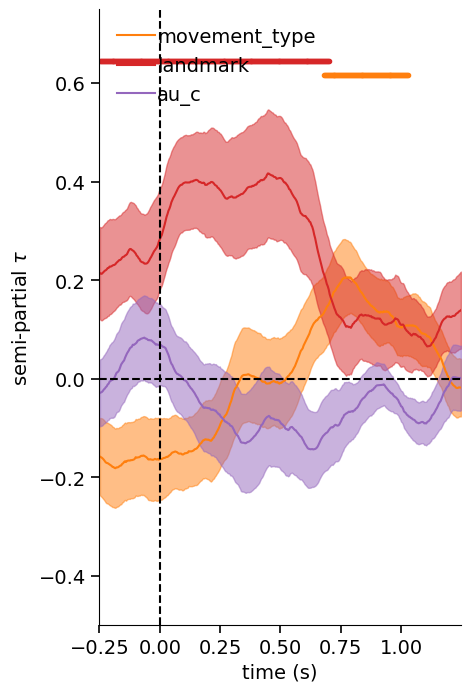

In [22]:
plt.rcParams.update({
    'font.size': 14,
    'axes.spines.right': False,
    'axes.spines.top': False,
    'xtick.major.size': 6,
    'xtick.major.width': 1.2,
    'ytick.major.size': 6,
    'ytick.major.width': 1.2,
    'legend.frameon': False,
    'legend.handletextpad': 0.1,
    'svg.fonttype': 'none',
    'text.usetex': False
})

plt.figure(figsize=(4.67, 8))
ax = plt.subplot(1, 1, 1)

times=epochs_per_model[test_models[0]].times
cluster_t_idxs=[]

for c_idx, c_type in enumerate(test_models[:3]):
    model_corr_data=np.mean(epochs_per_model[c_type].get_data()*1e6,axis=1)

    cluster_stats = mne.stats.permutation_cluster_1samp_test(
        model_corr_data,
        out_type='mask',
        n_permutations=10000,
        buffer_size=None,
        tail=1,
        n_jobs=-1
    )

    # Unpack the results
    t_obs, clusters, cluster_p_values, H0 = cluster_stats
    
    # Find significant clusters
    significant_clusters = np.where(cluster_p_values < 0.05)[0]

    cluster_t_idx = []
    for i in range(len(significant_clusters)):
        mask = clusters[significant_clusters[i]]
        cluster_t_idx.append(np.arange(len(times))[mask])
    if len(cluster_t_idx):
        cluster_t_idx=np.hstack(cluster_t_idx)
        cluster_t_idxs.append(cluster_t_idx)
    else:
        cluster_t_idxs.append([])
        
    m_ch_corrs = np.mean(model_corr_data, axis=0)
    se_ch_corrs = np.std(model_corr_data, axis=0)/np.sqrt(model_corr_data.shape[0])

    plt.plot(times, m_ch_corrs, label=c_type, color=condition_colors[c_type])
    plt.fill_between(times, m_ch_corrs-se_ch_corrs, m_ch_corrs+se_ch_corrs, alpha=0.5, color=condition_colors[c_type])
    
yl=plt.ylim()
pos_range=yl[1]

plt.axhline(0,color='k',linestyle='--')
plt.axvline(0,color='k',linestyle='--')

for c_idx,t_idx in enumerate(cluster_t_idxs):        
    c_type=test_models[c_idx]
    for t in t_idx:
        plt.plot(times[t], yl[1]+.05*pos_range+.05*pos_range*c_idx, '.', color=condition_colors[c_type])
    
plt.xlim(times[[0,-1]])
plt.ylim([-0.5, 0.75])

plt.xlabel('time (s)')
plt.ylabel(r'semi-partial $\tau$')

plt.legend(loc='upper left')

plt.savefig('../output/RSA_9m_static_movement_type.pdf')
plt.savefig('../output/RSA_9m_static_movement_type.png')

In [35]:
def _find_sig_windows(sig, times):
    """
    Convert a boolean significance mask (T,) into a list of consecutive time windows.
    Returns list of tuples: (t_start, t_end, idx_array)
    """
    sig = np.asarray(sig, dtype=bool)
    if sig.size == 0 or not sig.any():
        return []

    d = np.diff(np.concatenate(([0], sig.view(np.int8), [0])))
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]  # exclusive
    windows = []
    for s, e in zip(starts, ends):
        idx = np.arange(s, e)
        windows.append((times[s], times[e - 1], idx))
    return windows
    
def plot_correlation(c_idx, time_win, column):
    model_data = epochs_per_model[test_models[c_idx]].get_data() * 1e6
    clus_corr = np.mean(model_data, axis=1)
    times = epochs_per_model[test_models[c_idx]].times#+win_sz_ms/2/1000
    t_idx = np.where((times >= time_win[0]) & (times <= time_win[1]))[0]
    
    behav_vals = np.array(filtered_df[column].values)
    corr_vals = np.mean(clus_corr[:, t_idx], axis=-1)

    plt.rcParams.update({
        'font.size': 14,
        'axes.spines.left': True,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'xtick.major.size': 6,
        'xtick.major.width': 1.2,
        'ytick.major.size': 6,
        'ytick.major.width': 1.2,
        'legend.frameon': False,
        'legend.handletextpad': 0.1,
        'svg.fonttype': 'none',
        'text.usetex': False
    })
        
    # Prepare to plot
    plt.figure()
    plt.scatter(behav_vals, corr_vals, color='blue', alpha=0.5, label='Data points')
    plt.xlabel(column)
    plt.ylabel(test_models[c_idx])

    # Bootstrap linear regression for prediction CI
    n_bootstraps = 10000
    predictions = []
    x_vals = np.linspace(min(behav_vals), max(behav_vals), 100)
    
    for _ in range(n_bootstraps):
        sample_indices = resample(np.arange(len(behav_vals)))
        sample_behav = behav_vals[sample_indices]
        sample_corr = corr_vals[sample_indices]
        slope, intercept, _, _, _ = linregress(sample_behav, sample_corr)
        pred_y = slope * x_vals + intercept
        predictions.append(pred_y)

    predictions = np.array(predictions)
    ci_lower = np.percentile(predictions, 2.5, axis=0)
    ci_upper = np.percentile(predictions, 97.5, axis=0)
    
    # Plot mean prediction line
    mean_predictions = np.mean(predictions, axis=0)
    plt.plot(x_vals, mean_predictions, 'r-', label='Regression Line')
    
    # Add shaded confidence interval
    plt.fill_between(x_vals, ci_lower, ci_upper, color='gray', alpha=0.2, label='95% CI')
    
    plt.show()

    # Spearman correlation and p-value
    stat, p_val = spearmanr(behav_vals, corr_vals)
    print(f'rho={stat}, p={p_val}')

def _spearman_r_all_time_fast(x, Y):
    """
    Spearman correlation between x (n,) and each column of Y (n x T),
    computed as Pearson correlation on ranks (average ranks for ties).
    Returns r (T,).
    """
    n = x.shape[0]

    rx = rankdata(x)  # (n,)
    rY = np.apply_along_axis(rankdata, 0, Y)  # (n, T)

    # z-score ranks
    rx = (rx - rx.mean()) / rx.std(ddof=1)
    rY = (rY - rY.mean(axis=0)) / rY.std(axis=0, ddof=1)

    # Pearson corr per column
    return (rx[:, None].T @ rY / (n - 1)).ravel()


def perm_test_spearman_maxstat_one_sided(
    clus_corr,          # (n_subj, T) neural summary (e.g., channel-mean tau timecourse)
    behav,              # (n_subj,) behavioural vector with possible NaNs
    n_perm=10000,
    alpha=0.05,
    rng_seed=0
):
    """
    One-sided (positive) permutation test with max-statistic FWER correction over time.

    Returns
    -------
    real_r : (T,) observed Spearman r at each time point
    thr    : float, global (over-time) threshold from max null distribution
    sig    : (T,) boolean, significant time points where real_r > thr
    """
    rng = np.random.default_rng(rng_seed)

    valid = np.isfinite(behav)
    x = behav[valid].astype(float)
    Y = clus_corr[valid, :].astype(float)

    n = x.shape[0]
    T = Y.shape[1]
    if n < 5:
        # Too few points for stable correlation / permutation inference
        return np.full((T,), np.nan), np.nan, np.zeros((T,), dtype=bool)

    # Precompute ranked & z-scored Y once (big speed win)
    rY = np.apply_along_axis(rankdata, 0, Y)
    rY = (rY - rY.mean(axis=0)) / rY.std(axis=0, ddof=1)

    # Rank & z-score x once; permute its ranks under the null
    rx = rankdata(x)
    rx = (rx - rx.mean()) / rx.std(ddof=1)

    # Observed stat
    real_r = (rx[:, None].T @ rY / (n - 1)).ravel()

    # Permutation max-stat null
    max_stats = np.zeros((n_perm,), dtype=float)
    for p in range(n_perm):
        prx = rx[rng.permutation(n)]
        perm_r = (prx[:, None].T @ rY / (n - 1)).ravel()
        max_stats[p] = np.nanmax(perm_r)  # one-sided positive: max over time

    thr = np.percentile(max_stats, 100 * (1 - alpha))
    sig = real_r > thr

    return real_r, thr, sig

def cluster_based_permutation_test(
    c_idx,
    columns,
    behavior_colors,
    suffix='',
    num_permutations=10000,
    alpha=0.05,
    rng_seed=42
):
    # Neural summary: subject x time
    model_data = epochs_per_model[test_models[c_idx]].get_data() * 1e6
    clus_corr = np.mean(model_data, axis=1)  # (subjects, times)
    times = epochs_per_model[test_models[c_idx]].times

    per_col = []  # list of dicts with results per column

    for i, column in enumerate(columns):
        behav = filtered_df[column].values.astype(float)  # keep NaNs

        real_r, thr, sig = perm_test_spearman_maxstat_one_sided(
            clus_corr=clus_corr,
            behav=behav,
            n_perm=num_permutations,
            alpha=alpha,
            rng_seed=rng_seed,
        )

        windows = _find_sig_windows(sig, times)  # list of (t0, t1, idx)
        per_col.append(
            dict(
                column=column,
                color=behavior_colors[column],
                real_r=real_r,
                thr=thr,
                sig=sig,
                sig_idx=np.where(sig)[0],
                windows=windows,
            )
        )

    plt.rcParams.update({
        'font.size': 14,
        'axes.spines.left': True,
        'axes.spines.right': False,
        'axes.spines.top': False,
        'xtick.major.size': 6,
        'xtick.major.width': 1.2,
        'ytick.major.size': 6,
        'ytick.major.width': 1.2,
        'legend.frameon': False,
        'legend.handletextpad': 0.1,
        'svg.fonttype': 'none',
        'text.usetex': False
    })
    fig = plt.figure(figsize=(4.67, 6))
    
    for item in per_col:
        plt.plot(times, item["real_r"], label=item["column"], color=item["color"])

    # Reference lines
    plt.axhline(0, color="black", linestyle="--")
    plt.axvline(0, color="black", linestyle="--")
    
    # Significance dots (stacked by behavioural series index)
    yl = plt.ylim()
    pos_range = yl[1] - yl[0] if yl[1] > yl[0] else 1.0
    base = yl[1] + 0.05 * pos_range

    for i, item in enumerate(per_col):
        sig_idx = item["sig_idx"]
        for t in sig_idx:
            if times[t]>0:
                plt.plot(times[t], base + 0.05 * pos_range * i, ".", color=item["color"])

    plt.ylim([-.6, 1.0])
    plt.legend(loc="lower right")
    plt.xlabel("Time (s)")
    plt.ylabel("{}: Spearman r".format(test_models[c_idx]))

    # Save time-series
    fig_base = "../output/behav_corr_9m_static_movement_type_{}{}".format(test_models[c_idx],suffix)
    plt.savefig(fig_base + ".pdf")
    plt.savefig(fig_base + ".png", dpi=600)

    # Show time-series now (optional)
    plt.show()
    
    # --- 3) Make scatter plots AFTER the time-series is finished
    for item in per_col:
        for (t0, t1, _) in item["windows"]:
            if t1>0:
                plot_correlation(
                    c_idx=c_idx,
                    time_win=(t0, t1),
                    column=item["column"],
                )

    return per_col



In [36]:
csv_file_path = os.path.join(out_base_path,'behavior_2m.csv')

# Read the CSV file into a DataFrame
df = pd.read_csv(csv_file_path)
subjects_used = [int(subject) for subject in subjects_used]
filtered_df = df[df['subject'].isin([int(subject) for subject in subjects_used])]

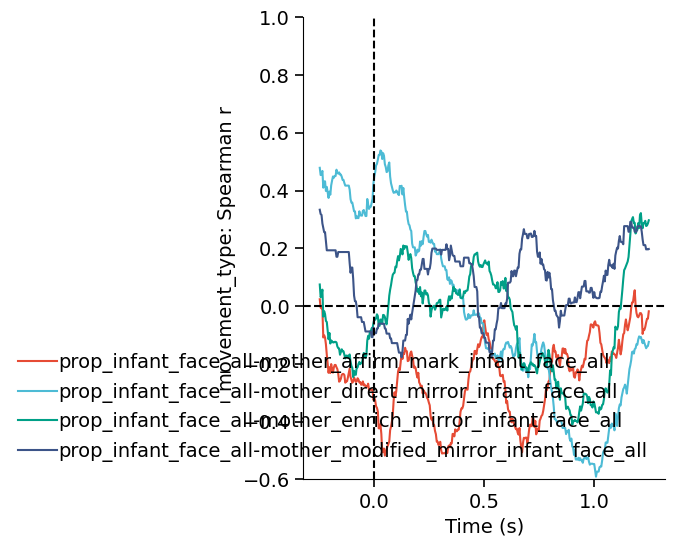

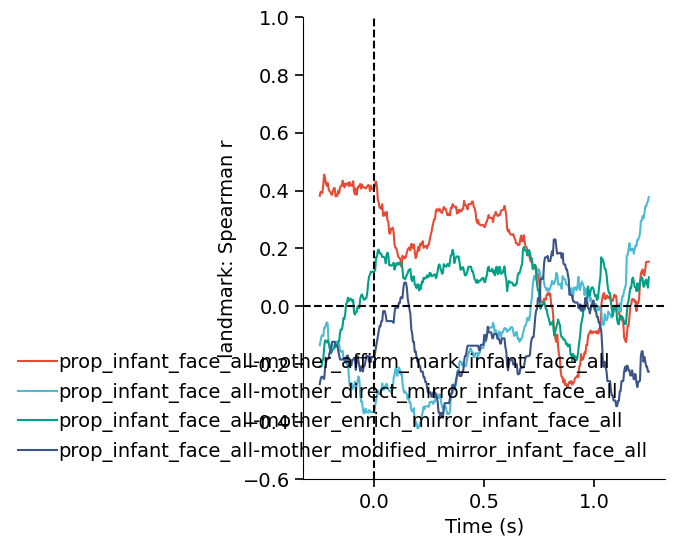

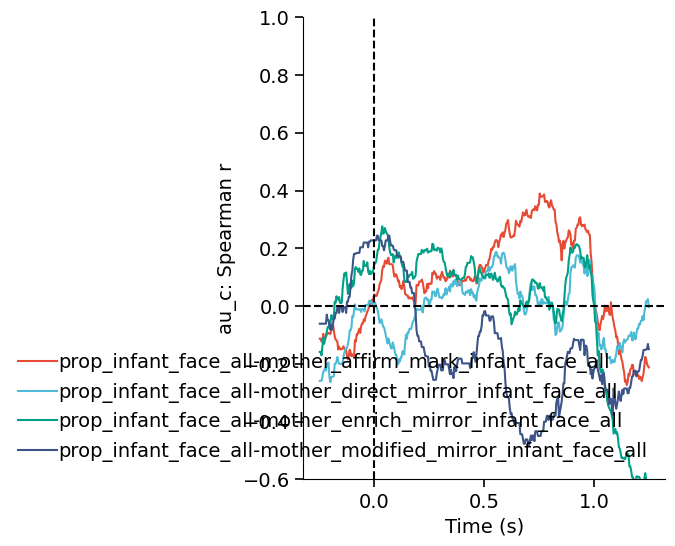

In [37]:
columns=[
    'prop_infant_face_all-mother_affirm_mark_infant_face_all',
    'prop_infant_face_all-mother_direct_mirror_infant_face_all',
    'prop_infant_face_all-mother_enrich_mirror_infant_face_all',
    'prop_infant_face_all-mother_modified_mirror_infant_face_all'
]
behavior_colors = {
    'prop_infant_face_all-mother_affirm_mark_infant_face_all': '#E64B35',   # red-orange (marking)
    'prop_infant_face_all-mother_direct_mirror_infant_face_all': '#4DBBD5', # cyan
    'prop_infant_face_all-mother_enrich_mirror_infant_face_all': '#00A087', # teal-green
    'prop_infant_face_all-mother_modified_mirror_infant_face_all': '#3C5488' # dark blue
}
for i in range(3):
    cluster_based_permutation_test(i, columns, behavior_colors)

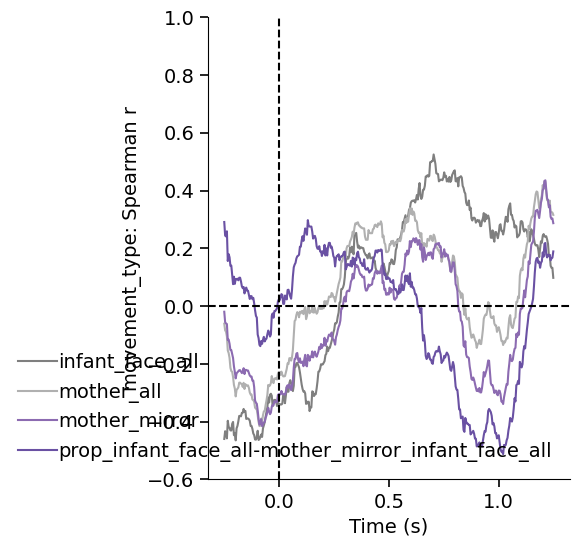

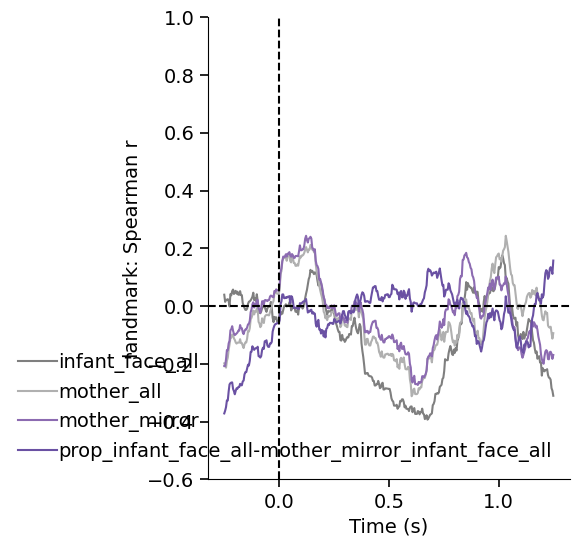

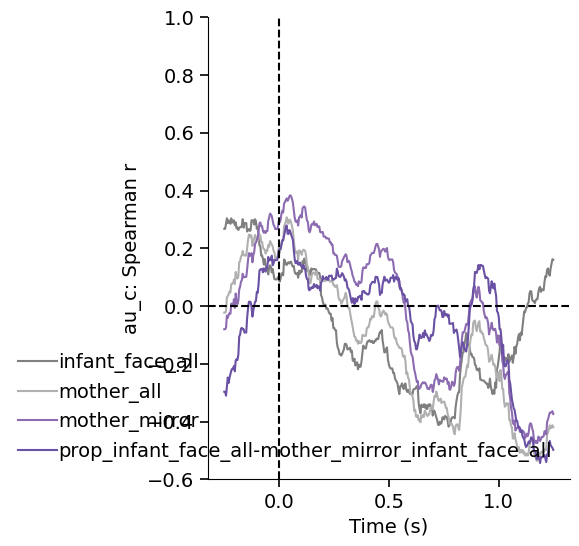

In [38]:
columns=[
    'infant_face_all',
    'mother_all',
    'mother_mirror',
    'prop_infant_face_all-mother_mirror_infant_face_all'
]
control_behavior_colors = {
    'infant_face_all': '#7F7F7F',   # mid grey
    'mother_all': '#B0B0B0',        # light grey
    'mother_mirror': '#8C6BB1',     # muted purple
    'prop_infant_face_all-mother_mirror_infant_face_all': '#6A51A3'  # darker purple
}
for i in range(3):
    cluster_based_permutation_test(i, columns, control_behavior_colors, suffix='_control')